In [ ]:

import pandas as pd

data = {
    "session_id": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "page": [
        "Home", "Products", "Cart", "Home", "Products",
        "Checkout", "Home", "Products", "Cart", "Home"
    ],
    "page_views": [5, 4, 2, 3, 6, 2, 1, 5, 3, 4],
    "session_duration": [180, 240, 90, 60, 300, 120, 25, 260, 100, 200],
    "exit_page": [
        "Products", "Cart", "Cart", "Home", "Checkout",
        "Checkout", "Home", "Cart", "Cart", "Products"
    ],
    "converted": [1, 1, 0, 0, 1, 1, 0, 0, 0, 1]
}

df = pd.DataFrame(data)
df.to_csv("website_traffic.csv", index=False)

print("Dataset created successfully!")
display(df)


Dataset created successfully!


,session_id,page,page_views,session_duration,exit_page,converted
0,1,Home,5,180,Products,1
1,2,Products,4,240,Cart,1
2,3,Cart,2,90,Cart,0
3,4,Home,3,60,Home,0
4,5,Products,6,300,Checkout,1
5,6,Checkout,2,120,Checkout,1
6,7,Home,1,25,Home,0
7,8,Products,5,260,Cart,0
8,9,Cart,3,100,Cart,0
9,10,Home,4,200,Products,1


In [ ]:

# Total number of sessions
total_sessions = df["session_id"].nunique()

# Total page views recorded
total_page_views = df["page_views"].sum()

# Average session duration in seconds
avg_duration = df["session_duration"].mean()

# Total conversions
total_conversions = df["converted"].sum()

# Conversion rate
conversion_rate = (total_conversions / total_sessions) * 100

print("Total Sessions:", total_sessions)
print("Total Page Views:", total_page_views)
print("Average Session Duration:", round(avg_duration, 2), "seconds")
print("Total Conversions:", total_conversions)
print("Conversion Rate:", round(conversion_rate, 2), "%")


Total Sessions: 10
Total Page Views: 35
Average Session Duration: 157.5 seconds
Total Conversions: 5
Conversion Rate: 50.0 %


Page-wise Traffic:
page
Cart         5
Checkout     2
Home        13
Products    15
Name: page_views, dtype: int64


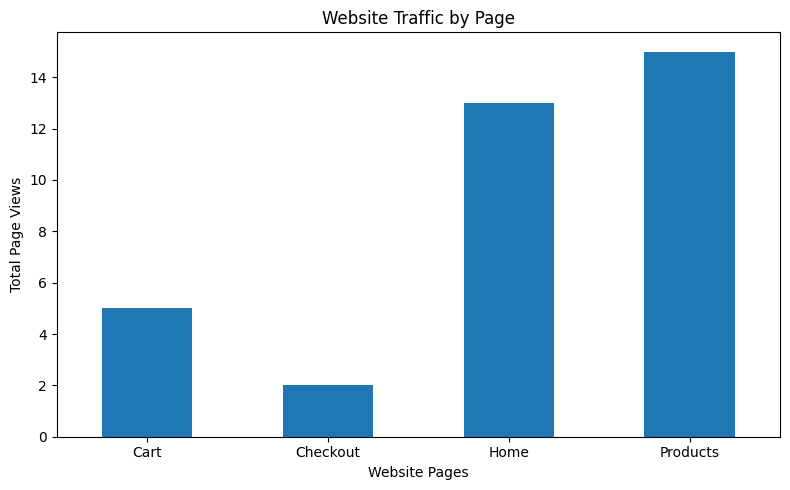

In [ ]:

import matplotlib.pyplot as plt

# Calculate total page views for each page
page_traffic = df.groupby("page")["page_views"].sum()

print("Page-wise Traffic:")
print(page_traffic)

# Create a bar graph
plt.figure(figsize=(8, 5))
page_traffic.plot(kind="bar")

plt.title("Website Traffic by Page")
plt.xlabel("Website Pages")
plt.ylabel("Total Page Views")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Average Session Duration by Page (seconds):
page
Cart         95.00
Checkout    120.00
Home        116.25
Products    266.67
Name: session_duration, dtype: float64


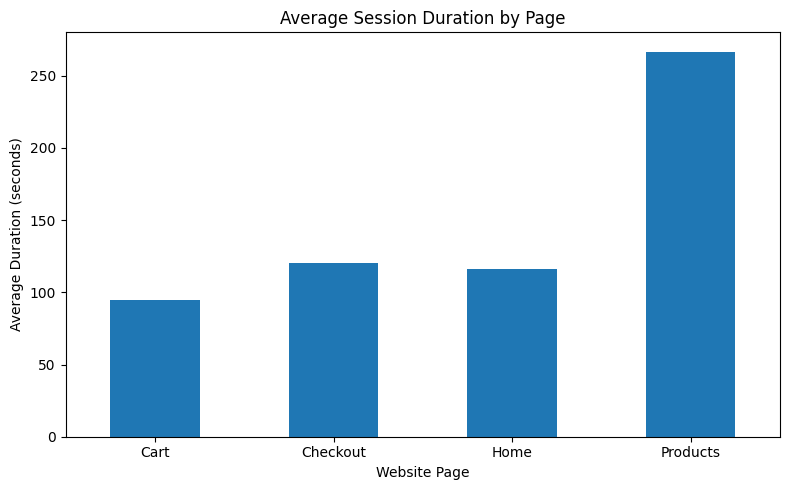

In [ ]:

# Calculate average session duration for each page
duration_by_page = df.groupby("page")["session_duration"].mean()

print("Average Session Duration by Page (seconds):")
print(duration_by_page.round(2))

# Create a bar graph
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
duration_by_page.plot(kind="bar")

plt.title("Average Session Duration by Page")
plt.xlabel("Website Page")
plt.ylabel("Average Duration (seconds)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Website Exit Analysis:
exit_page
Cart        4
Products    2
Home        2
Checkout    2
Name: count, dtype: int64

Exit Percentage:
exit_page
Cart        40.0
Products    20.0
Home        20.0
Checkout    20.0
Name: count, dtype: float64


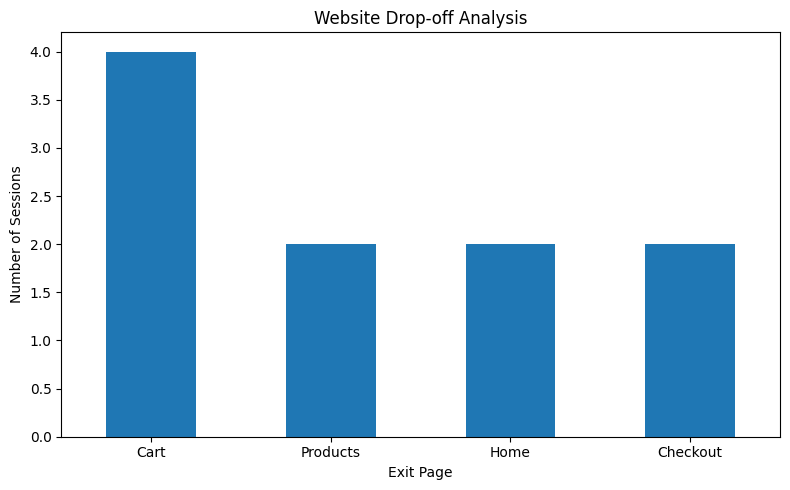

In [ ]:

# Count exits from each page
exit_counts = df["exit_page"].value_counts()

print("Website Exit Analysis:")
print(exit_counts)

# Calculate percentage of exits
exit_percentage = (exit_counts / len(df)) * 100

print("\nExit Percentage:")
print(exit_percentage.round(2))

# Visualize exit points
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
exit_counts.plot(kind="bar")

plt.title("Website Drop-off Analysis")
plt.xlabel("Exit Page")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

# Analyze user journeys using the sample session data

journey = df.groupby("session_id").agg(
    pages_visited=("page", lambda x: " -> ".join(x)),
    total_page_views=("page_views", "sum"),
    duration=("session_duration", "first"),
    exit_page=("exit_page", "last"),
    converted=("converted", "max")
)

print("User Journey Analysis:")
display(journey)

# Count conversions
conversion_summary = df.groupby("converted")["session_id"].count()

print("\nConversion Summary:")
print("Not Converted:", conversion_summary.get(0, 0))
print("Converted:", conversion_summary.get(1, 0))


User Journey Analysis:


,pages_visited,total_page_views,duration,exit_page,converted
session_id,,,,,
1,Home,5,180,Products,1
2,Products,4,240,Cart,1
3,Cart,2,90,Cart,0
4,Home,3,60,Home,0
5,Products,6,300,Checkout,1
6,Checkout,2,120,Checkout,1
7,Home,1,25,Home,0
8,Products,5,260,Cart,0
9,Cart,3,100,Cart,0



Conversion Summary:
Not Converted: 5
Converted: 5


User Journey Transitions:


,From,To,Sessions
0,Home,Products,8
1,Products,Cart,6
2,Cart,Checkout,3
3,Home,Products,4
4,Products,Cart,2
5,Cart,Exit,3


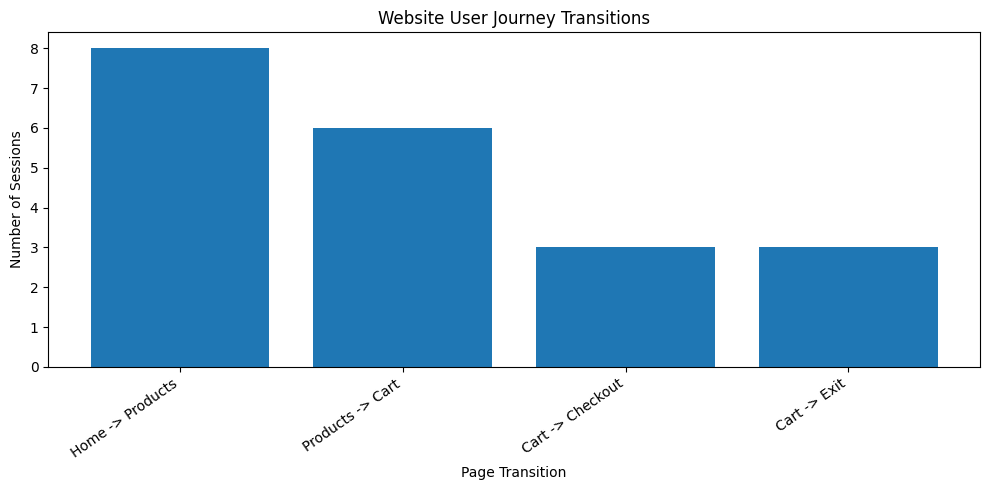

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Sample user journey transitions
journeys = {
    "From": [
        "Home", "Products", "Cart",
        "Home", "Products", "Cart"
    ],
    "To": [
        "Products", "Cart", "Checkout",
        "Products", "Cart", "Exit"
    ],
    "Sessions": [8, 6, 3, 4, 2, 3]
}

journey_df = pd.DataFrame(journeys)

print("User Journey Transitions:")
display(journey_df)

# Plot page-to-page transitions
journey_df["Transition"] = (
    journey_df["From"] + " -> " + journey_df["To"]
)

plt.figure(figsize=(10, 5))
plt.bar(
    journey_df["Transition"],
    journey_df["Sessions"]
)

plt.title("Website User Journey Transitions")
plt.xlabel("Page Transition")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
